## Functions

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import os

### Extimate params

In [59]:
# specify if want to reutn a fit, or just the arams

def bestfit_fourier_params(
    t_raw,
    y,
    N=25,
    time_unit="auto",          # "auto", "s", "us", "ms", or float scale factor (e.g. 1e-6)
    center_time=False,    # change
    robust=True,
    max_nfev=400,
    return_fit=True,    # put True to receive the fitted function too !!!!
    plot=False,
):
    """
    Fit a Fourier series to data, optimizing only frequency f and time-shift t0,
    while solving Fourier coefficients linearly for each (f, t0).
    
    Returns a params dict compatible with your waveform generators:
        params = {"f0": f_opt, "A": A_opt, "offset": offset_opt, "phi0": 0.0, ...}

    Notes:
    - This fit is a *general Fourier series* (cos+sin), not specifically a square.
      So phi0 is not uniquely defined; we return phi0=0 and provide t0 + beta.
    - If you want a square/triangle/sawtooth with your param-style, use f0 + t0.
    """

    # ----------------------------
    # 1) time conversion to seconds
    # ----------------------------
    t_raw = np.asarray(t_raw, dtype=float)
    y = np.asarray(y, dtype=float)

    t = t_raw.copy()

    if isinstance(time_unit, (int, float)):          # user gives scale factor to seconds
        t = t * float(time_unit)
    else:
        tu = str(time_unit).lower()
        if tu == "s":
            pass
        elif tu == "us":
            t = t * 1e-6
        elif tu == "ms":
            t = t * 1e-3
        elif tu == "auto":
            # heuristic: if big numbers -> assume microseconds
            if np.nanmax(t) > 1000:
                t = t * 1e-6
        else:
            raise ValueError("time_unit must be 'auto', 's', 'us', 'ms', or a numeric scale factor")

    if center_time:
        t = t - np.nanmin(t)

    # ----------------------------
    # 2) initial frequency guess via FFT
    # ----------------------------
    dt = np.median(np.diff(t))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Time array must be increasing and contain at least 2 points.")

    y_detr = y - np.mean(y)
    Y = np.fft.rfft(y_detr)
    freqs = np.fft.rfftfreq(len(y_detr), d=dt)

    k0 = 1
    k_peak = k0 + np.argmax(np.abs(Y[k0:]))
    f0_guess = float(freqs[k_peak]) if freqs[k_peak] > 0 else 1.0

    # ----------------------------
    # 3) design matrix + linear solve
    # ----------------------------
    def design_matrix(tt, omega, t0):
        tau = tt - t0
        cols = [np.ones_like(tt)]
        for n in range(1, N + 1):
            cols.append(np.cos(n * omega * tau))
            cols.append(np.sin(n * omega * tau))
        return np.column_stack(cols)

    def fit_linear_coeffs(tt, yy, omega, t0):
        X = design_matrix(tt, omega, t0)
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        yhat = X @ beta
        return beta, yhat

    def residuals_nonlinear(p):
        log_f, t0 = p
        f = np.exp(log_f)
        omega = 2 * np.pi * f
        _, yhat = fit_linear_coeffs(t, y, omega, t0)
        return (yhat - y)

    # ----------------------------
    # 4) nonlinear fit (log_f, t0)
    # ----------------------------
    p0 = np.array([np.log(f0_guess), 0.0])

    ls_kwargs = dict(
        fun=residuals_nonlinear,
        x0=p0,
        max_nfev=max_nfev,
    )
    if robust:
        ls_kwargs.update(
            loss="soft_l1",
            f_scale=float(np.std(y)) if np.std(y) > 0 else 1.0,
        )

    res = least_squares(**ls_kwargs)

    log_f_opt, t0_opt = res.x
    f_opt = float(np.exp(log_f_opt))
    omega_opt = 2 * np.pi * f_opt

    beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, float(t0_opt))

    # ----------------------------
    # 5) readable params (like your previous ones)
    # ----------------------------
    offset_opt = float(beta_opt[0])
    A_pp = float(np.max(yhat_opt) - np.min(yhat_opt))
    A_opt = 0.5 * A_pp

    # For "phi0": not uniquely meaningful for a general Fourier fit,
    # but if you want to use your sin-based generators, the *time shift* is the key.
    # You can map t0 into an equivalent fundamental phase shift:
    phi0_equiv = float(-omega_opt * t0_opt)  # so sin(ω(t - t0)) = sin(ωt + phi0_equiv)

    params = {
        "f0": f_opt,
        "A": A_opt,
        "offset": offset_opt,
        "phi0": phi0_equiv,   # usable with your sin-based series
        # extras (often useful)
        "t0": float(t0_opt),
        "N": int(N),
        "beta": beta_opt,     # [c0, a1,b1,a2,b2,...]
        "rmse": float(np.sqrt(np.mean((yhat_opt - y) ** 2))),
        "success": bool(res.success),
        "cost": float(res.cost),
    }

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(t, y, linewidth=1.5, label="data")
        plt.plot(t, yhat_opt, linewidth=2.5, label="best-fit Fourier")
        plt.grid(True, alpha=0.3)
        plt.xlabel("t (s)")
        plt.ylabel("y")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if return_fit:
        return params, t, yhat_opt
    return params


### Create with Fourier

In [60]:
def square_wave_fourier(t, N_harm=50, **params):
    """
    Square wave via Fourier series.
    params can contain:
        f0, A, offset, phi0, t0
    """

    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    phi0 = params.get("phi0", None)
    t0   = params.get("t0", None)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    for k in range(1, N_harm + 1, 2):

        if t0 is not None:
            w += (4 / (np.pi * k)) * np.sin(k * omega * (t - t0))
        elif phi0 is not None:
            w += (4 / (np.pi * k)) * np.sin(k * (omega * t + phi0))
        else:
            w += (4 / (np.pi * k)) * np.sin(k * omega * t)

    return offset + A * w


In [61]:
def triangle_wave_fourier(t, N_harm=50, **params):
    """
    Square wave via Fourier series.
    params can contain:
        f0, A, offset, phi0, t0
    """

    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    phi0 = params.get("phi0", None)
    t0   = params.get("t0", None)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    for k in range(1, N_harm + 1, 2):
        sign = (-1)**((k - 1)//2)

        if t0 is not None:
            w += sign * (8 / (np.pi**2 * k**2)) * np.sin(k * omega * (t -t0))

        elif phi0 is not None:
            w += sign * (8 / (np.pi**2 * k**2)) * np.sin(k * (omega * t + phi0))
        else:
            w +=  sign * (8 / (np.pi**2 * k**2)) * np.sin(k * omega * t)

    return offset + A * w


In [62]:
# How to pass params

params = {
  'f0': 3098.7521483188,
  'A': 300.45022591575946,
  'offset': 1840.8297055689695,
  'phi0': 1.9,
}

In [63]:
# Pulse train : onda quadra a duty variabile

def pulse_train_fourier(t, f0=1.0, A=1.0, offset=0.0, t0=0.0, duty=0.5, N_harm=50):
    """
    Pulse train (square wave with variable duty cycle) via Fourier series.

    Signal model (ideal, before offset):
        +A  for phase in [0, duty)
        -A  for phase in [duty, 1)

    So the peak-to-peak is 2A, and for duty=0.5 it reduces to the classic square wave.
    """

    duty = float(duty)
    if not (0.0 < duty < 1.0):
        raise ValueError("duty must be in (0,1)")

    omega0 = 2*np.pi*f0

    # --- DC of the +/-A pulse train is A*(2D-1)
    # because mean = (+A)*D + (-A)*(1-D) = A(2D-1)
    x = np.full_like(t, fill_value=A*(2.0*duty - 1.0), dtype=float)

    for n in range(1, N_harm + 1):
        an = (2.0*A/(n*np.pi)) * np.sin(2.0*np.pi*n*duty)
        bn = (2.0*A/(n*np.pi)) * (1.0 - np.cos(2.0*np.pi*n*duty))
        x += an * np.cos(n*omega0* (t - t0)) + bn * np.sin(n*omega0* (t - t0))

    return offset + x


### Integrator

In [64]:
def rc_lowpass_H(omega, fc):
    """
    RC low-pass transfer function H(jw) = 1 / (1 + j*w/wc)
    """
    wc = 2*np.pi*fc
    return 1.0 / (1.0 + 1j * (omega / wc))

In [65]:
# Integrate a square wave
# need a full func, bc need to modify the coeffs while i'm writing it
# asks if want retues all the gains, can use them to plot
# this only works with t0, don't support phi0

def rc_integrator_output_from_square_fourier(t, f0=1.0, A=1.0, offset=0.0, t0=0.0,
                                             fc=10.0, N_harm=51, want_gain=False):
    """
    Square wave -> RC low-pass (integrator-ish) output computed in Fourier domain.
    - Keeps DC component (offset) correctly.
    - Applies |H(j n w0)| and phase arg(H) to each harmonic.
    """

    omega0 = 2*np.pi*f0
    y_ac = np.zeros_like(t, dtype=float)
    gains = []


    for n in range(1, N_harm + 1, 2):
        omega_n = n * omega0

        # input harmonic amplitude for square: A * (4/pi) * (1/n)
        amp_in = A * (4.0/np.pi) * (1.0/n)

        Hn = rc_lowpass_H(omega_n, fc)
        gain = np.abs(Hn)
        phase = np.angle(Hn)  # negative for low-pass

        # harmonic with time shift t0:
        y_ac += (amp_in * gain) * np.sin(omega_n * (t - t0) + phase)
        gains.append(gain)

    # DC passes with gain 1 for RC low-pass
    y = offset + y_ac

    if want_gain:
        return y, gains[0]
    
    else:  
        return y


In [66]:
def rc_integrator_output_from_triangle_fourier(t, f0=1.0, A=1.0, offset=0.0, t0=0.0,
                                               fc=10.0, N_harm=51, want_gain=False):
    """
    Triangular wave -> RC low-pass output computed in Fourier domain.
    """
    omega0 = 2*np.pi*f0
    y_ac = np.zeros_like(t, dtype=float)
    gains = []
    for n in range(1, N_harm + 1, 2):
        omega_n = n * omega0

        # input harmonic amplitude for triangle:
        amp_in = A * (8.0/np.pi**2) * ((-1)**((n-1)//2)) * (1.0/n**2)

        Hn = rc_lowpass_H(omega_n, fc)
        gain = np.abs(Hn)
        phase = np.angle(Hn)

        y_ac += (amp_in * gain) * np.sin(omega_n * (t - t0) + phase)
        gains.append(gain)

    y = offset + y_ac

    if want_gain:
        return y, gains[0]
    else:
        return y

In [67]:
def rc_lowpass_output_from_pulse_fourier(t, f0=1.0, A=1.0, offset=0.0, t0=0.0,
                                        duty=0.5, fc=10.0, N_harm=50):
    """
    Pulse train -> RC low-pass output computed in Fourier domain.

    - Keeps DC correctly (DC passes with gain 1).
    - For each harmonic n: apply complex H(j n w0) to the cosine/sine coefficients.

    Returns
    -------
    y : array
        filtered output
    """
    duty = float(duty)
    if not (0.0 < duty < 1.0):
        raise ValueError("duty must be in (0,1)")

    omega0 = 2*np.pi*f0
    tau = (t - t0)

    # DC component of the pulse (passes unchanged through low-pass)
    y = np.full_like(t, fill_value=offset + A*(2.0*duty - 1.0), dtype=float)

    # Harmonics
    for n in range(1, N_harm + 1):
        omega_n = n * omega0

        an = (2.0*A/(n*np.pi)) * np.sin(2.0*np.pi*n*duty)
        bn = (2.0*A/(n*np.pi)) * (1.0 - np.cos(2.0*np.pi*n*duty))

        Hn = rc_lowpass_H(omega_n, fc)
        Hr = np.real(Hn)
        Hi = np.imag(Hn)

        # If input has an*cos + b*sin, then after multiplying by H=Hr+iHi:
        # cos coefficient becomes: a' = a*Hr + b*Hi
        # sin coefficient becomes: b' = b*Hr - a*Hi
        a_out = an*Hr + bn*Hi
        b_out = bn*Hr - an*Hi

        y += a_out * np.cos(omega_n*tau) + b_out * np.sin(omega_n*tau)

    return y



In [68]:
# used it??? 


def triangle_and_output(t, f0, A, offset, t0, fc, N_harm=51):
    x = triangle_wave_fourier(t, f0=f0, A=A, offset=offset, t0=t0, N_harm=N_harm)
    y = rc_integrator_output_from_triangle_fourier(t, f0=f0, A=A, offset=offset, t0=t0, fc=fc, N_harm=N_harm)
    return x, y

def square_and_sharkfin(t, f0, A, offset, t0, fc, N_harm=51):
    x = square_wave_fourier(t, f0=f0, A=A, offset=offset, t0=t0, N_harm=N_harm)
    y = rc_integrator_output_from_square_fourier(t, f0=f0, A=A, offset=offset, t0=t0, fc=fc, N_harm=N_harm)
    return x, y

def pulse_and_lowpass(t, f0, A, offset, t0, duty, fc, N_harm=50):
    x = pulse_train_fourier(t, f0=f0, A=A, offset=offset, t0=t0, duty=duty, N_harm=N_harm)
    y = rc_lowpass_output_from_pulse_fourier(t, f0=f0, A=A, offset=offset, t0=t0, duty=duty, fc=fc, N_harm=N_harm)
    return x, y


In [69]:
# how to pass params: it don't support **params, must pass them one by one
# 
# y_out, gain = rc_integrator_output_from_square_fourier(
#        t,                         # x = array tempi (s)
#        f0=freq,
#        A=params1["A"],
#        offset=params1["offset"],
#        t0=params1["t0"],
#        fc=params1['fc'],
#        N_harm=N_harm,
#        want_gain=True              # massima armonica (odd)
#    )


### Derivator

In [70]:
def rc_highpass_H(omega, fc):
    """
    RC high-pass transfer function H(jw) = (j*w/wc) / (1 + j*w/wc)
    """
    wc = 2*np.pi*fc
    s = 1j * (omega / wc)
    return s / (1.0 + s)

In [71]:
def rc_derivator_output_from_square_fourier(t, f0=1.0, A=1.0, offset=0.0, t0=0.0,
                                            fc=10.0, N_harm=51, want_gain=False):
    """
    Square wave -> RC high-pass (differentiator-ish) output computed in Fourier domain.

    - DC (offset) is blocked by the capacitor -> output has NO offset term.
    - Applies |H_HP(j n w0)| and phase arg(H_HP) to each harmonic.
    """
    omega0 = 2*np.pi*f0
    y = np.zeros_like(t, dtype=float)
    gains = []

    for n in range(1, N_harm + 1, 2):
        omega_n = n * omega0

        # square wave harmonic amplitude (same as before)
        amp_in = A * (4.0/np.pi) * (1.0/n)

        Hn = rc_highpass_H(omega_n, fc)
        gain = np.abs(Hn)
        phase = np.angle(Hn)

        y += (amp_in * gain) * np.sin(omega_n * (t - t0) + phase)
        gains.append(gain)

    # NOTE: no "+ offset" because HP blocks DC
    
    if want_gain:
        return y, gains[0]
    else: 
        return y

In [72]:
# Used it?

def square_and_derivativeish(t, f0, A, offset, t0, fc, N_harm=51):
    x = square_wave_fourier(t, f0=f0, A=A, offset=offset, t0=t0, N_harm=N_harm)
    y = rc_derivator_output_from_square_fourier(t, f0=f0, A=A, offset=offset, t0=t0, fc=fc, N_harm=N_harm)
    return x, y

### Other

In [73]:
def rms_error(y, y_ref):
    return np.sqrt(np.mean((y - y_ref)**2))   # MSE, mean squared error

In [74]:
def make_axes(N_list):
    fig, axes = plt.subplots(
        nrows=len(N_list),
        ncols=1,
        sharex=True,
        figsize=(12, 2.2 * len(N_list)),
        constrained_layout=True
    )
    return fig, axes

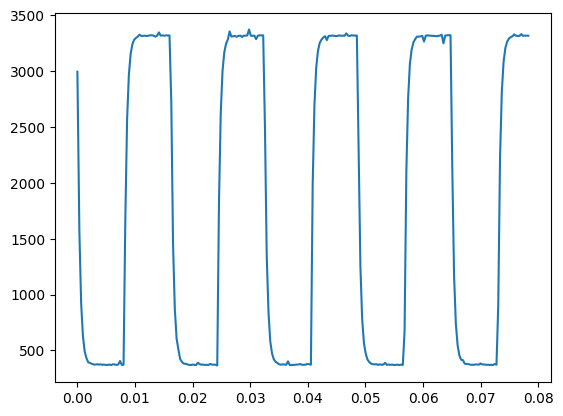

In [75]:
# Upload files with similar name

Directory = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'

x_list = []
y_list = []

for i in range(1, 10):   # 1 ... 9
    filename = f'integratore_{i}.txt'
    path = os.path.join(Directory, filename)

    x, y = np.loadtxt(path, unpack=True)
    x = (x - x[0]) * 1e-6   # microsecondi → secondi

    x_list.append(x)
    y_list.append(y)

# esempio d'uso
plt.plot(x_list[1], y_list[1])
plt.show()

## Part 1

### Square

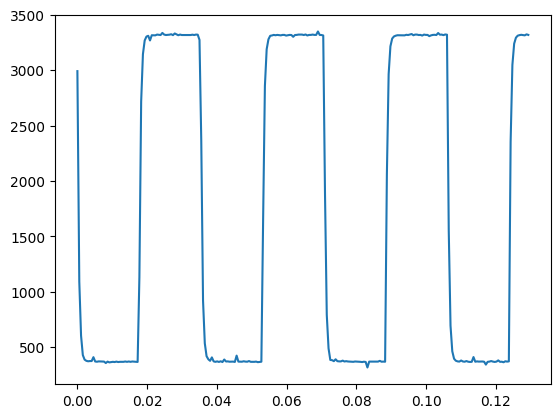

In [76]:
# Plot a file

Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'
NomeFile = 'integratore_1.txt'
path=(Directory+NomeFile)
x,y=np.loadtxt(path,unpack=True)
x = (x-x[0])* 1e-6  # turn into seconds

plt.plot(x,y)

In [77]:
# bestfit_fourier_params(x,y)

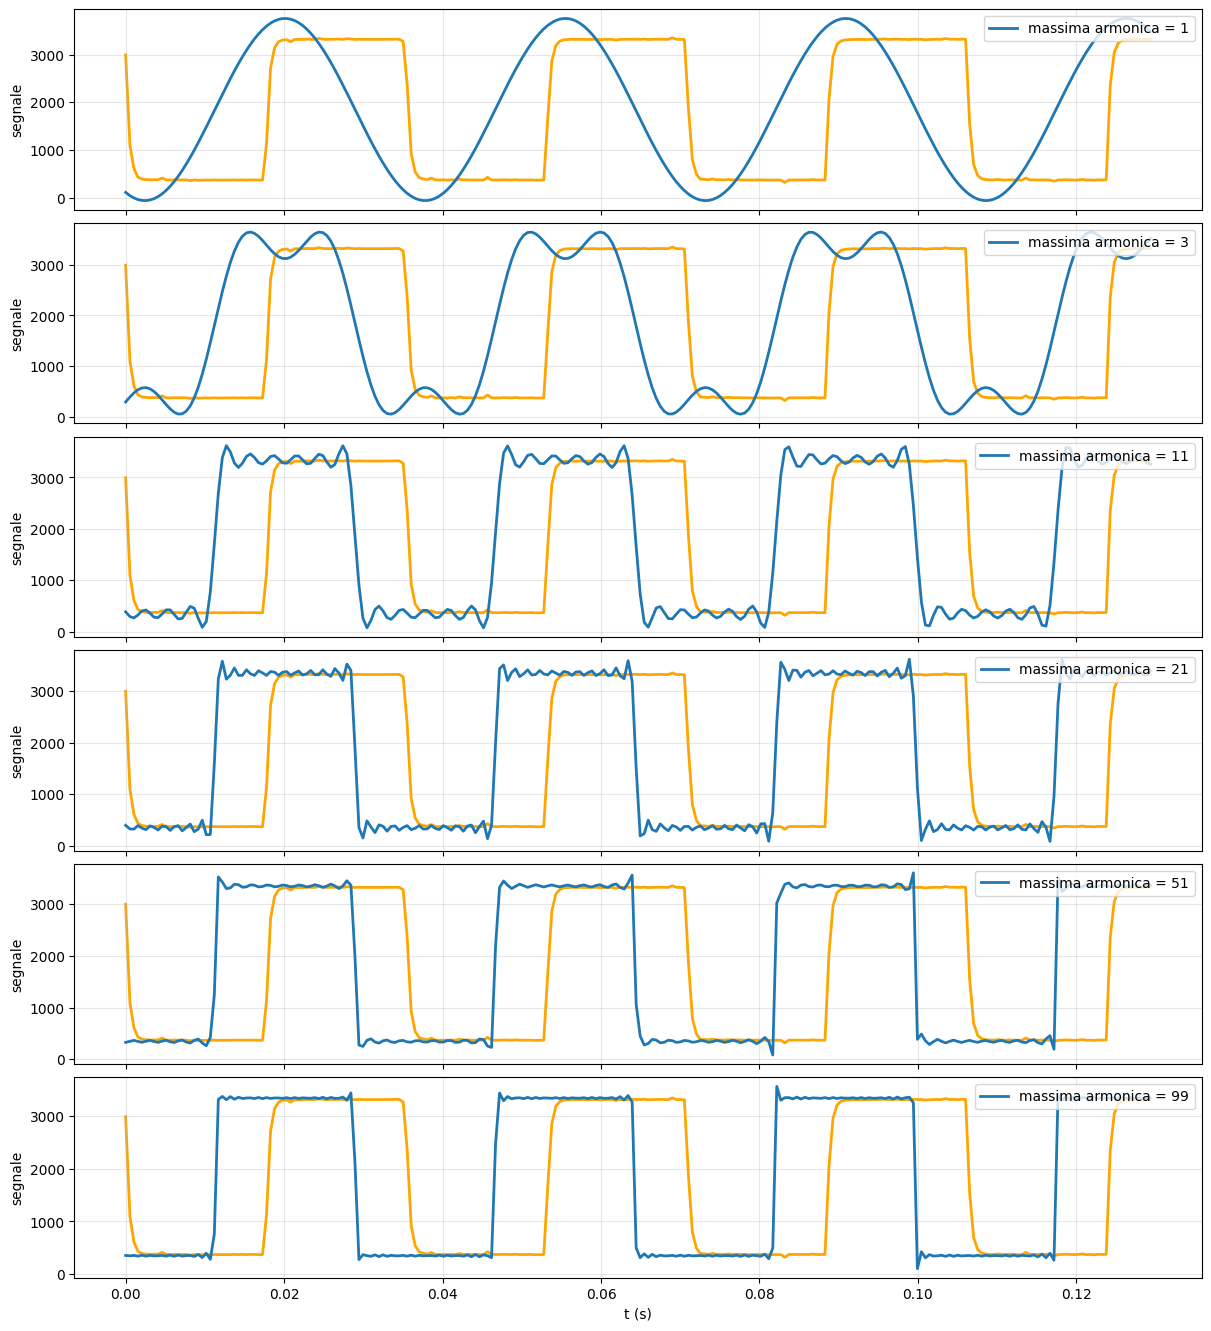

In [78]:
# Cambia massima armonica  

params1 = {'f0': 28.259064357714447,
  'A': 1500,
  'offset': 1846.4872060542261,
  'phi0': 3.1,
  't0': -302.2634308254316,
}

N_list=(1, 3, 11, 21, 51, 99)
rms_list = []

fig, axes = make_axes(N_list)

for ax, N_harm in zip(axes, N_list):
    t = square_wave_fourier(x, N_harm=N_harm, **params1)

    ax.plot(x, t, linewidth=2.0, label=f"massima armonica = {N_harm}")
    ax.plot(x,y, linewidth=2.0, zorder=1, color='orange')
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    
    rms = rms_error(y,t)
    rms_list.append(rms)


axes[-1].set_xlabel("t (s)")
plt.show()


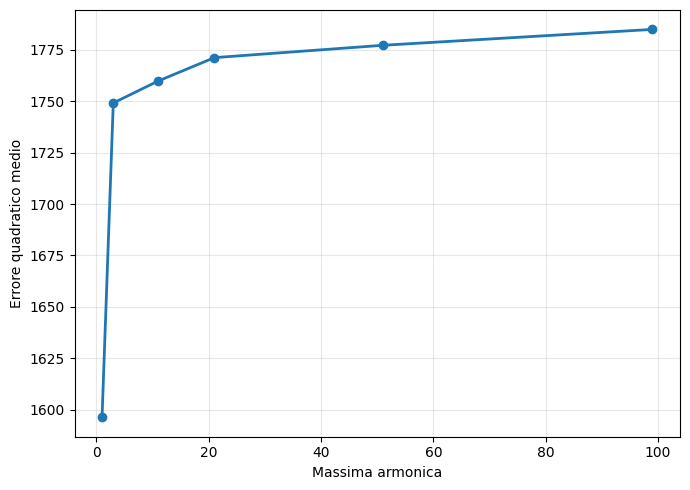

In [79]:
plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2)
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
# plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


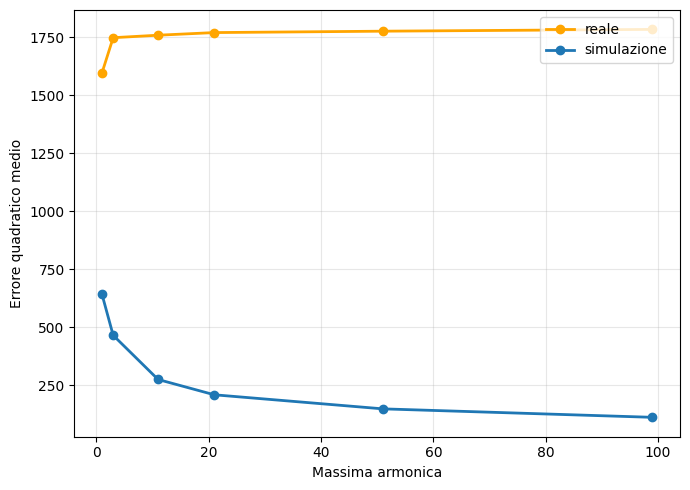

In [80]:
# Rms rispetto a onda fatta bene  

N_ref = 1000  
y_ref = square_wave_fourier(x, N_harm=N_ref, **params1)


rms_list_sim = []

for N in N_list:
    t = square_wave_fourier(x, N_harm=N, **params1)
    rms = rms_error(t, y_ref)
    rms_list_sim.append(rms)

plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2, color='orange', label='reale')
plt.plot(N_list, rms_list_sim, "o-", linewidth=2, label='simulazione')
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend(loc="upper right")
plt.show()

In [81]:
rms_list_sim

[np.float64(642.9116186256838),
 np.float64(464.98340337957393),
 np.float64(274.27563936809014),
 np.float64(208.30600440973816),
 np.float64(147.61980556904308),
 np.float64(111.0502028790525)]

alla fine rms aumenta, perchè approssimo meglio vicino ai salti, dove però la mia armonica misurata NON è corretta, perchè anche qella è approssimata, visto che è campionata    
quindi se campiono meno l'armonica, mi viene meglio

questo problema appare nella triangolare???  

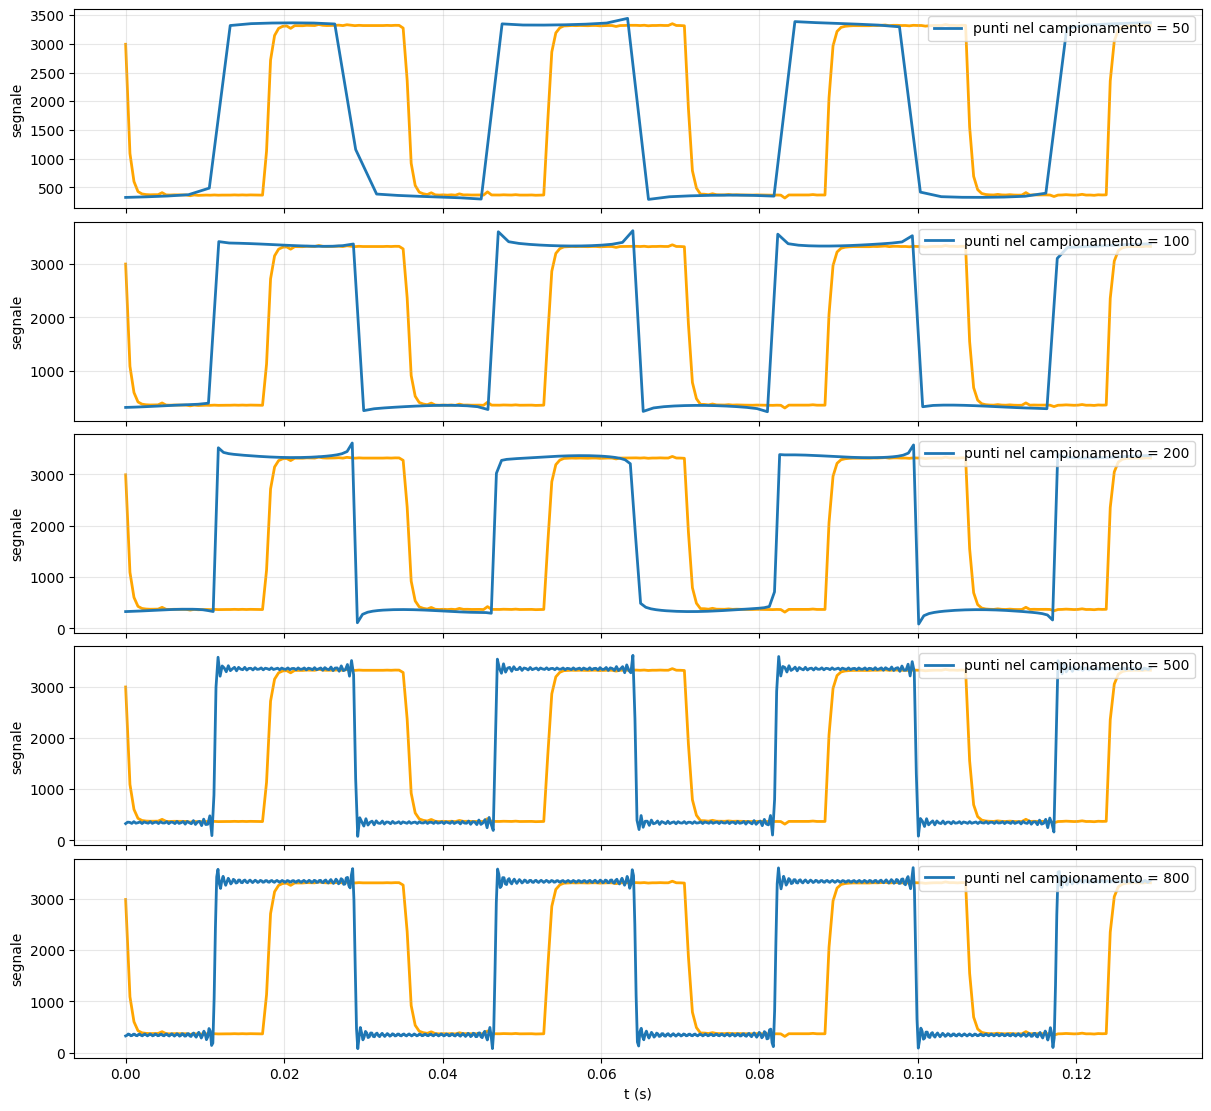

In [82]:
### Cambia campionamento

params1 = {'f0': 28.259064357714447,
  'A': 1500,
  'offset': 1846.4872060542261,
  'phi0': 3.1,
  't0': -302.2634308254316,
}

N_harm = 51
points_list = [50, 100, 200, 500, 800]
rms_list_p = []

fig, axes = make_axes(points_list)


x_start = x.min()
x_end   = x.max()

for ax, Np in zip(axes, points_list):
    x1 = np.linspace(x_start, x_end, Np)    # diversi campionamenti
    t = square_wave_fourier(x1, N_harm=N_harm, **params1)    # sul nuovo campionamento
    y1 = np.interp(x, x1, t)   # lungo x

    ax.plot(x1,t, linewidth=2.0, label=f"punti nel campionamento = {Np}")
    ax.plot(x,y, linewidth=2.0, zorder=1, color='orange')
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    rms = rms_error(y,y1)
    rms_list_p.append(rms)


axes[-1].set_xlabel("t (s)")
plt.show()

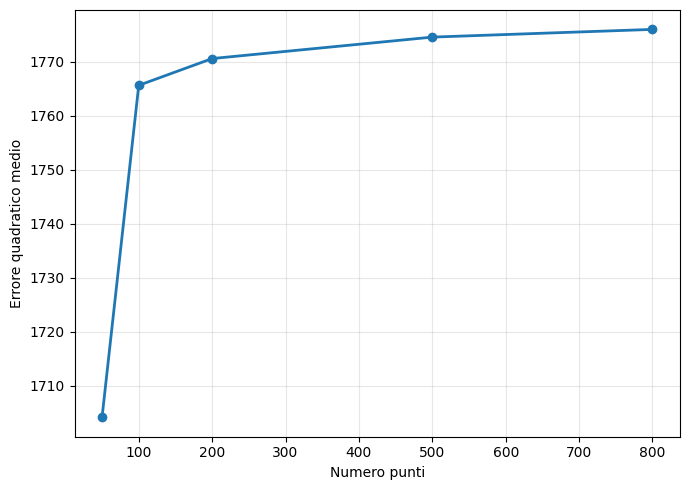

In [83]:
plt.figure(figsize=(7,5))
plt.plot(points_list, rms_list_p, "o-", linewidth=2)
plt.xlabel("Numero punti")
plt.ylabel("Errore quadratico medio")
# plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

se campiono troppo alto, copia troppo bene i punti di salto, aumenta l'errore  

### Triangle

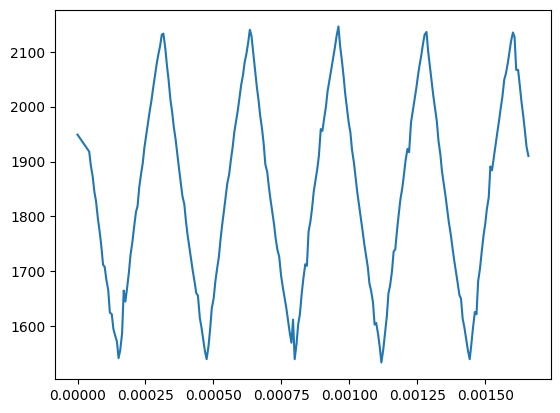

In [84]:
Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'
NomeFile = 'integratore_9.txt'
path=(Directory+NomeFile)
x,y=np.loadtxt(path,unpack=True)
x = (x-x[0])* 1e-6  # turn into seconds

plt.plot(x,y)



In [85]:
# bestfit_fourier_params(x,y)

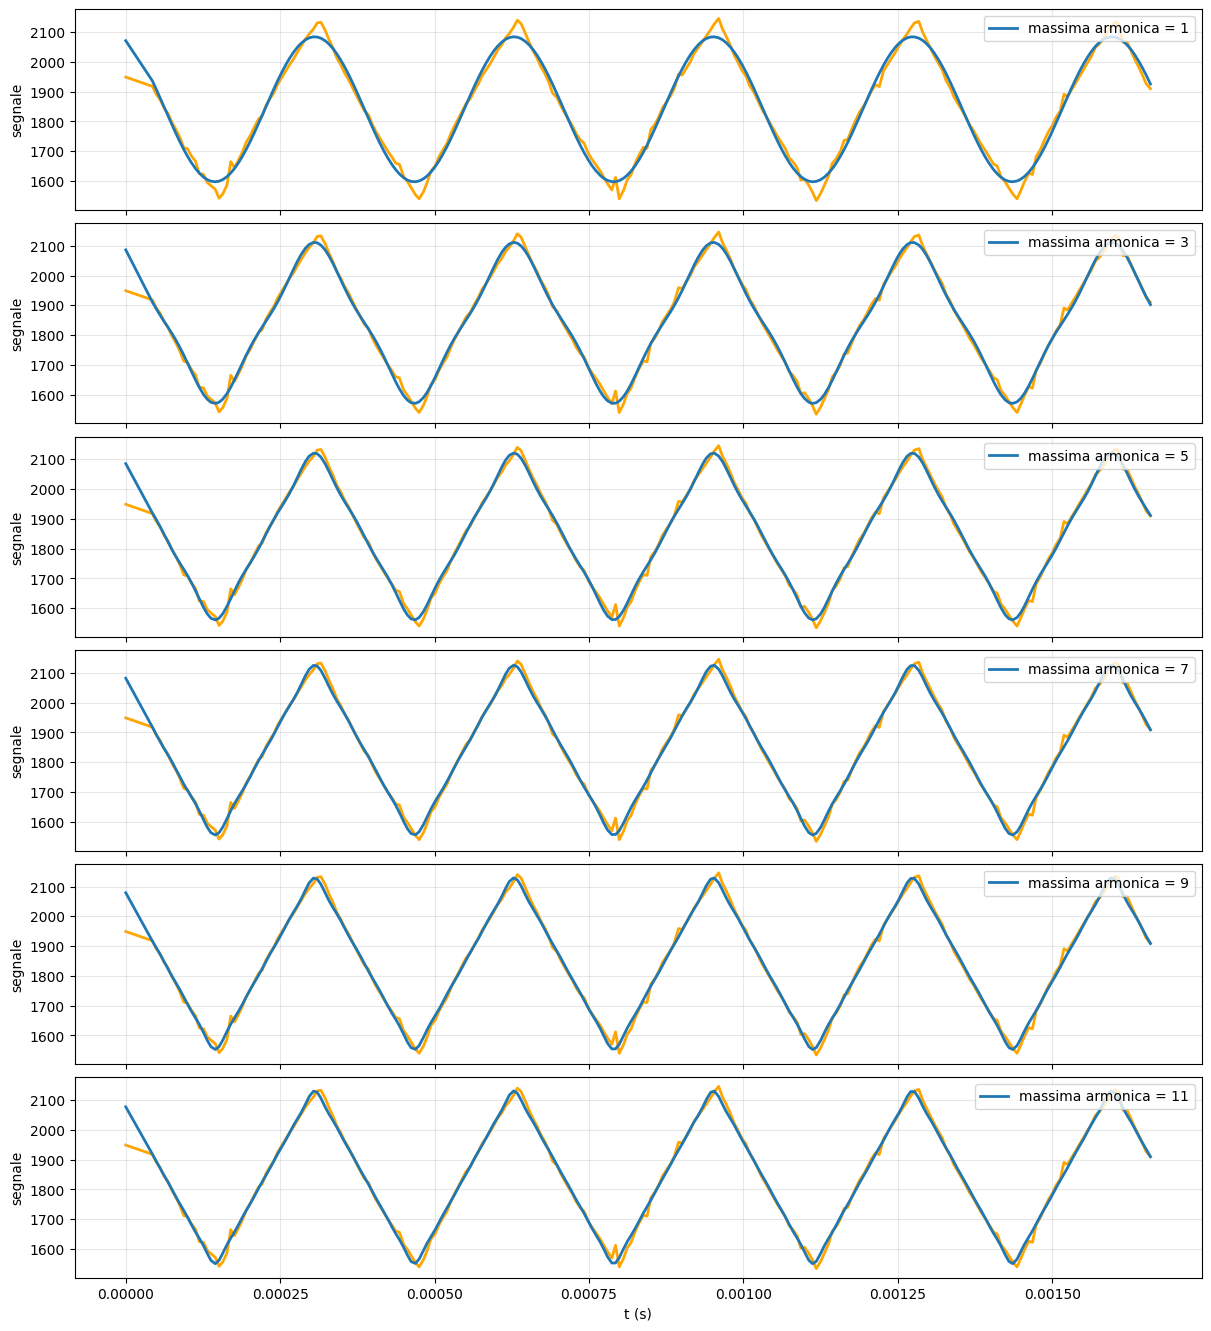

In [86]:
# Cambia massima armonica  

params1 = {'f0': 3098.7521483188,
  'A': 300.45022591575946,
  'offset': 1840.8297055689695,
  'phi0': 1.9,
}


N_list=(1, 3, 5, 7, 9, 11)
rms_list = []

fig, axes = make_axes(N_list)


# Se N_list ha un solo elemento, axes non è una lista: normalizziamo
if len(N_list) == 1:
    axes = [axes]

for ax, N_harm in zip(axes, N_list):
    t = triangle_wave_fourier(x, N_harm=N_harm, **params1)

    ax.plot(x, t, linewidth=2.0, label=f"massima armonica = {N_harm}")
    ax.plot(x,y, linewidth=2.0, zorder=1, color='orange')
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    rms = rms_error(y,t)
    rms_list.append(rms)


axes[-1].set_xlabel("t (s)")
plt.show()

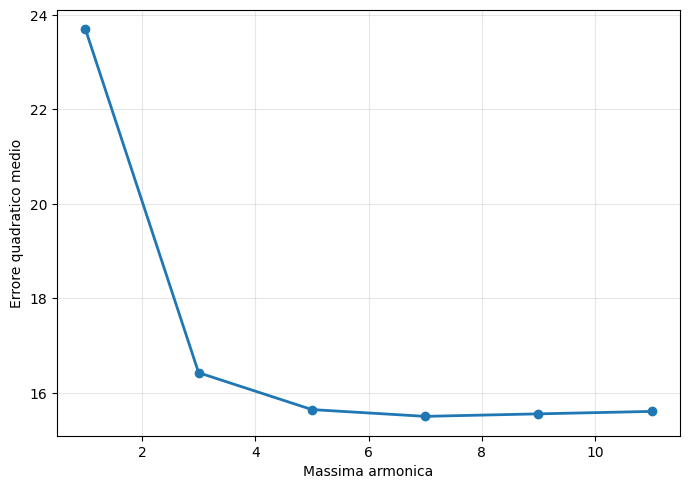

In [87]:
plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2)
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
# plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

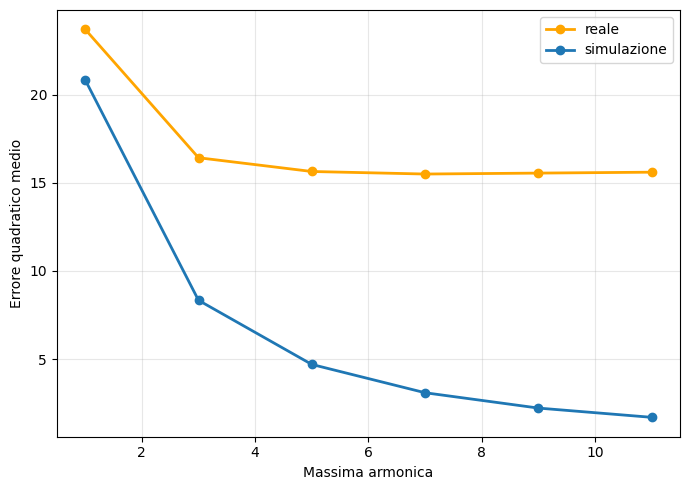

In [88]:
# Rms rispetto a onda fatta bene  

N_ref = 1000  
y_ref = triangle_wave_fourier(x, N_harm=N_ref, **params1)

rms_list_sim = []

for N in N_list:
    t = triangle_wave_fourier(x, N_harm=N, **params1)
    rms = rms_error(t, y_ref)
    rms_list_sim.append(rms)

plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2, color='orange', label='reale')
plt.plot(N_list, rms_list_sim, "o-", linewidth=2, label='simulazione')
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend(loc="upper right")
plt.show()

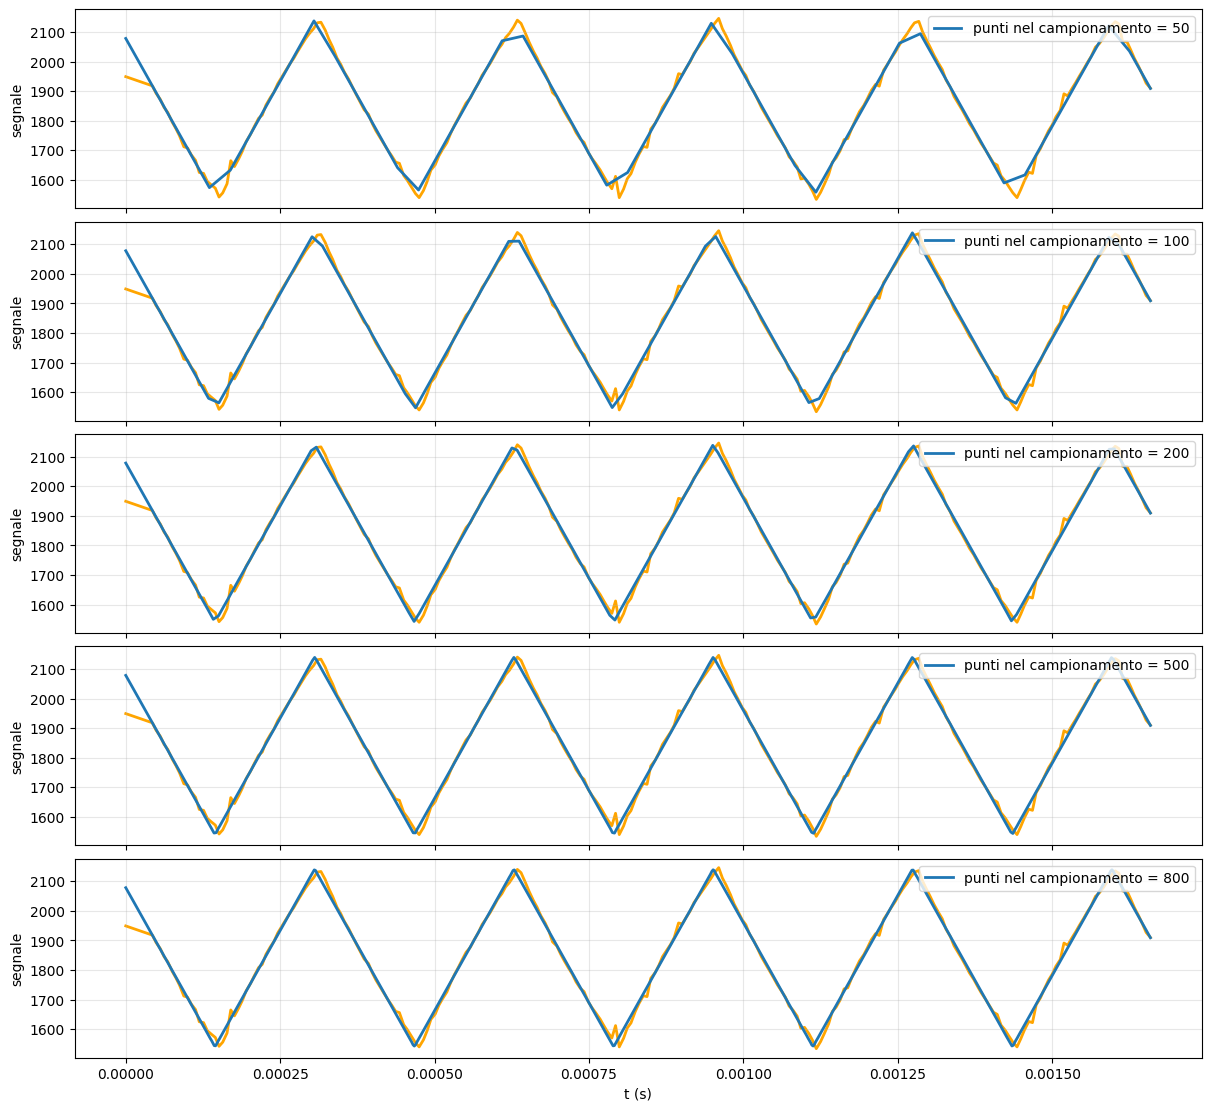

In [89]:
### Cambia campionamento


params1 = {'f0': 3098.7521483188,
  'A': 300.45022591575946,
  'offset': 1840.8297055689695,
  'phi0': 1.9,
}

N_harm = 51
points_list = [50, 100, 200, 500, 800]
rms_list_p = []

fig, axes = make_axes(points_list)


x_start = x.min()
x_end   = x.max()

for ax, Np in zip(axes, points_list):
    x1 = np.linspace(x_start, x_end, Np)    # diversi campionamenti
    t = triangle_wave_fourier(x1, N_harm=N_harm, **params1)    # sul nuovo campionamento
    y1 = np.interp(x, x1, t)   # lungo x

    ax.plot(x1,t, linewidth=2.0, label=f"punti nel campionamento = {Np}")
    ax.plot(x,y, linewidth=2.0, zorder=1, color='orange')
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    rms = rms_error(y,y1)
    rms_list_p.append(rms)


axes[-1].set_xlabel("t (s)")
plt.show()


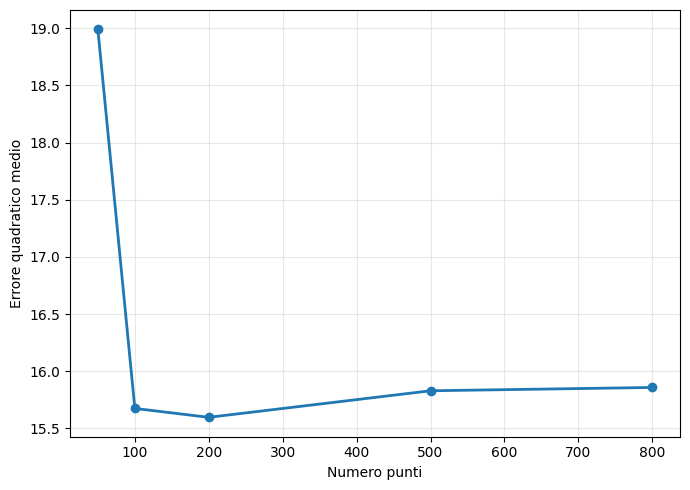

In [90]:
plt.figure(figsize=(7,5))
plt.plot(points_list, rms_list_p, "o-", linewidth=2)
plt.xlabel("Numero punti")
plt.ylabel("Errore quadratico medio")
# plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

triangolare ha problemi col campionamento, ma non con alte armoniche, semplicemente si stabilizza

## Part 3

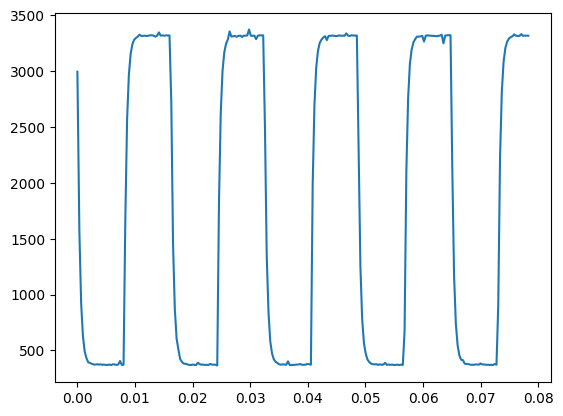

In [91]:
Directory = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'

x_list = []
y_list = []

for i in range(1, 10):   # 1 ... 9
    filename = f'integratore_{i}.txt'
    path = os.path.join(Directory, filename)

    x, y = np.loadtxt(path, unpack=True)
    x = (x - x[0]) * 1e-6   # microsecondi → secondi

    x_list.append(x)
    y_list.append(y)

# esempio d'uso
plt.plot(x_list[1], y_list[1])
plt.show()

In [92]:
# bestfit_fourier_params(x,y)

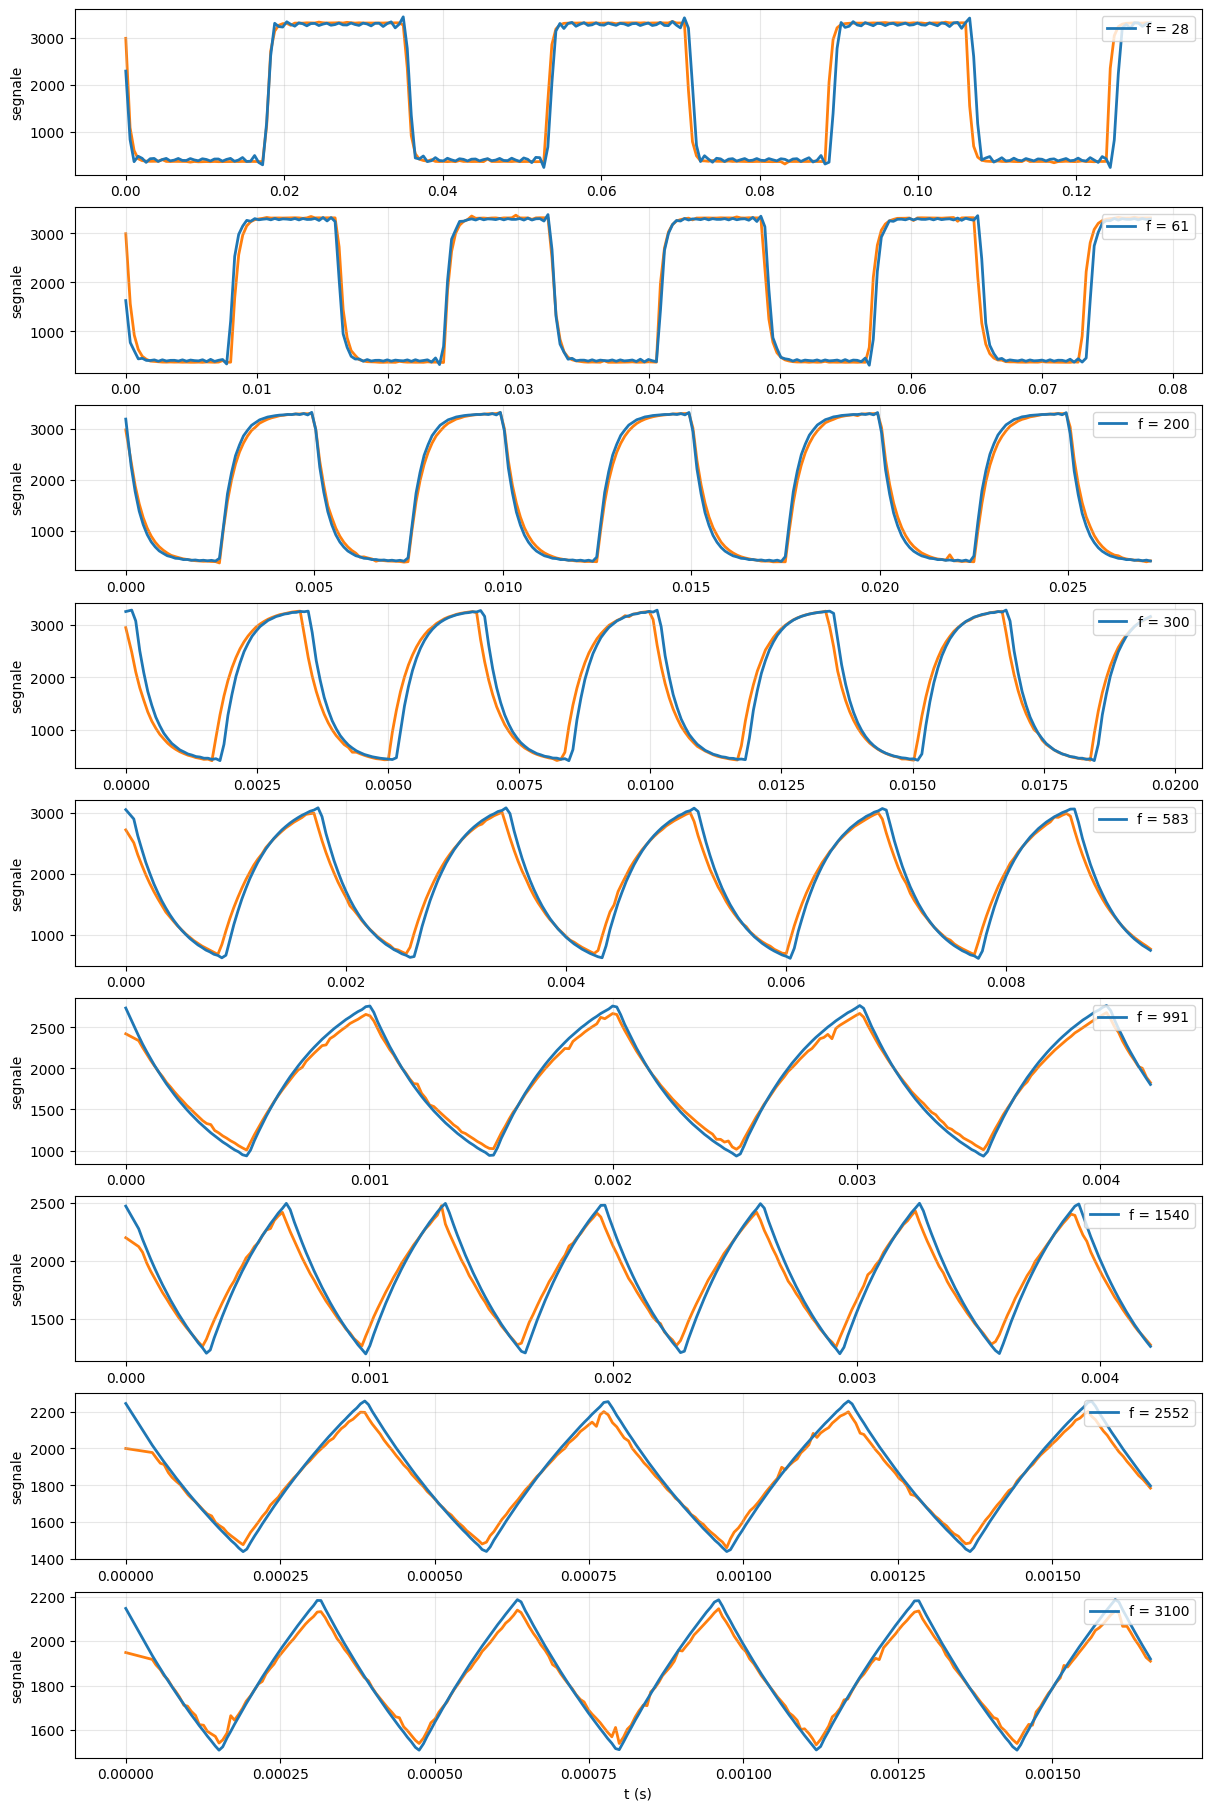

In [93]:
params1 = {'fc': 482,
  'A': 1442.065811231428,
  'offset': 1848.8752756447957,
  'phi0': -57303.22718660609,
  't0': -0.00017
}

freqs = [28, 61, 200, 300, 583, 991, 1540, 2552, 3100]
t0 =[-0.018,-0.0085,-0.0025,-0.0015,-0.00081,-0.00051,-0.00031,-0.0002,-0.00017]

nums = [0,1,2,3,4,5,6,7,8]
N_harm = 21
rms_list = []


fig, axes = plt.subplots(
    nrows=len(freqs),
    ncols=1,
    sharex=False,
    figsize=(12, 3 * len(N_list)),
    constrained_layout=True
)

def rms_error(y, y_ref):
    return np.sqrt(np.mean((y - y_ref)**2))   # MSE  


# Se N_list ha un solo elemento, axes non è una lista: normalizziamo
if len(freqs) == 1:
    axes = [axes]

for ax, freq, i, ti in zip(axes, freqs, nums, t0):

    y_hat = rc_integrator_output_from_square_fourier(
        x_list[i],                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=ti,
        fc=params1['fc'],
        N_harm=N_harm              # massima armonica (odd)
    )
    
    ax.plot(x_list[i], y_hat, linewidth=2.0, label=f"f = {freq}")
    ax.plot(x_list[i], y_list[i], linewidth=2.0, zorder=1)  # y = tuo segnale misurato
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

    rms_list.append(rms_error(y, y_hat))


axes[-1].set_xlabel("t (s)")
plt.show()

## Part 4

In [94]:
Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/'
NomeFile = 'guadagno.txt'
Filename=(Directory+NomeFile)
freqs, Vout=np.loadtxt(Filename,unpack=True)

In [95]:
Vin = 2.9
G_lab = Vout / Vin

In [96]:
# Simulate behaviour

G_sim = []
params1 = {
  'fc': 482,
  'A': 2.9,
  'offset': 1,
  'phi0': 0,
  't0': 0,
}
N_harm = 25

#fc è quella di prima??? non la sto passando???

for freq in freqs:  
    T = 1.0 / freq
    t = np.linspace(0, 10*T, 200)    # diversi campionamenti
    y_out, gain = rc_integrator_output_from_square_fourier(
        t,                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=params1["t0"],
        fc=params1['fc'],
        N_harm=N_harm,
        want_gain=True              # massima armonica (odd)
    )

    G_sim.append(gain)

In [97]:
G_sim

[np.float64(0.9980686594361383),
 np.float64(0.996062509144329),
 np.float64(0.9915209617293607),
 np.float64(0.9818862307268408),
 np.float64(0.9624229185616443),
 np.float64(0.9243202542053718),
 np.float64(0.856864854695711),
 np.float64(0.7510688935905404),
 np.float64(0.6137642854461791),
 np.float64(0.4710142295741074),
 np.float64(0.34290808757837915),
 np.float64(0.24261853016541607),
 np.float64(0.16882770737216263),
 np.float64(0.11656062451620083),
 np.float64(0.08010189728432136)]

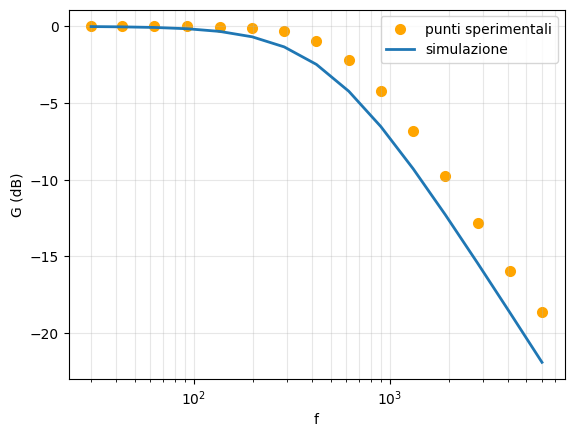

In [98]:
db_lab = 20 * np.log10(np.abs(G_lab))
db_sim = 20 * np.log10(np.abs(G_sim))
# if i put y_axis in log, there iss't the x20, is that  problem?  

plt.scatter(freqs, db_lab, linewidth=2, color='orange', label='punti sperimentali')
plt.plot(freqs, db_sim, linewidth=2, label='simulazione')

plt.xscale('log')
plt.ylabel('G (dB)')
plt.xlabel('f')
plt.grid(True, which='both', alpha=0.3)
plt.legend()

plt.show()

why can it go above the 0 line? isn't it impossible?   
maybe i caput put G/sim to 1 if they are bigger than 1?  
 
the version 2 is worse??? it doesn't have the straight part  

## Part 5

### Part 3

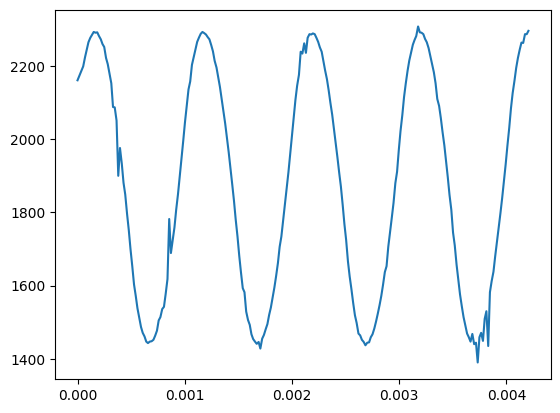

In [99]:
Directory = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'

x_list = []
y_list = []

for i in (1,4,6):  
    filename = f'integratore_triang_{i}.txt'
    path = os.path.join(Directory, filename)

    x, y = np.loadtxt(path, unpack=True)
    x = (x - x[0]) * 1e-6   # microsecondi → secondi

    x_list.append(x)
    y_list.append(y)

# esempio d'uso
plt.plot(x_list[2], y_list[2])
plt.show()

In [100]:
# bestfit_fourier_params(x,y)

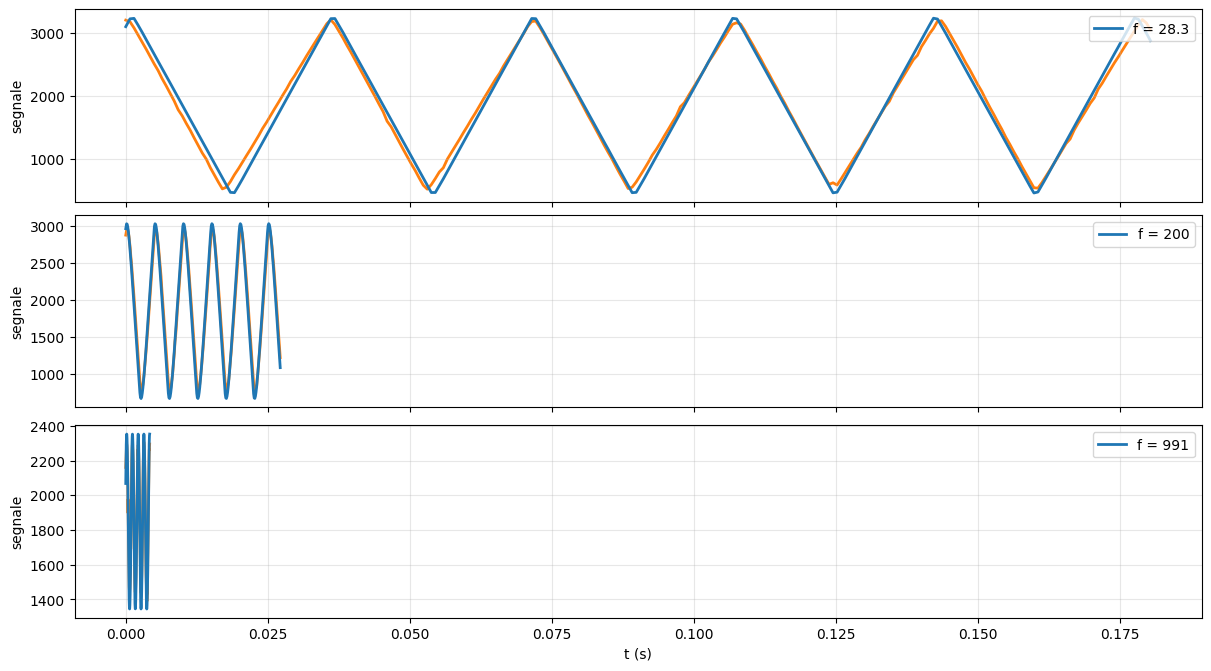

In [101]:
params1 = {'fc': 482,
  'A': 1442.065811231428,
  'offset': 1848.8752756447957,
  'phi0': -57303.22718660609,
  't0': -0.00017
}

freqs = [28.3, 200, 991]   # values 1,4,6 from before
t0 =[-0.008, -0.0063,-0.00025]

nums = [0,1,2]
N_harm = 21
rms_list = []

 #freqs = [28, 61, 200, 300, 583, 991, 1540, 2552, 3100]

fig, axes = make_axes(freqs)

for ax, freq, i, ti in zip(axes, freqs, nums, t0):

    y_hat = rc_integrator_output_from_triangle_fourier(
        x_list[i],                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=ti,
        fc=params1['fc'],
        N_harm=N_harm              # massima armonica (odd)
    )
    
    ax.plot(x_list[i], y_hat, linewidth=2.0, label=f"f = {freq}")
    ax.plot(x_list[i], y_list[i], linewidth=2.0, zorder=1)  # y = tuo segnale misurato
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

    rms_list.append(rms_error(y, y_hat))


axes[-1].set_xlabel("t (s)")
plt.show()

### Part 4

In [102]:
Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/'
NomeFile = 'guadagno_tri.txt'
Filename=(Directory+NomeFile)
freqs, Vout=np.loadtxt(Filename,unpack=True)

In [103]:
Vin = 2.9
G_lab = Vout / Vin

In [104]:
# Simulate behaviour

G_sim = []
params1 = {
  'fc': 482,
  'A': 2.9,
  'offset': 1,
  'phi0': 0,
  't0': 0,
}
N_harm = 25

#fc è quella di prima??? non la sto passando???

for freq in freqs:  
    T = 1.0 / freq
    t = np.linspace(0, 10*T, 200)    # diversi campionamenti
    y_out, gains = rc_integrator_output_from_triangle_fourier(
        t,                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=params1["t0"],
        fc=params1['fc'],
        N_harm=N_harm,              # massima armonica (odd)
        want_gain=True
    )

    G_sim.append(gains)

In [105]:
G_sim

[np.float64(0.9980686594361383),
 np.float64(0.996062509144329),
 np.float64(0.9915209617293607),
 np.float64(0.9818862307268408),
 np.float64(0.9624229185616443),
 np.float64(0.9243202542053718),
 np.float64(0.856864854695711),
 np.float64(0.7510688935905404),
 np.float64(0.6137642854461791),
 np.float64(0.4710142295741074),
 np.float64(0.34290808757837915),
 np.float64(0.24261853016541607),
 np.float64(0.16882770737216263),
 np.float64(0.11656062451620083),
 np.float64(0.08010189728432136)]

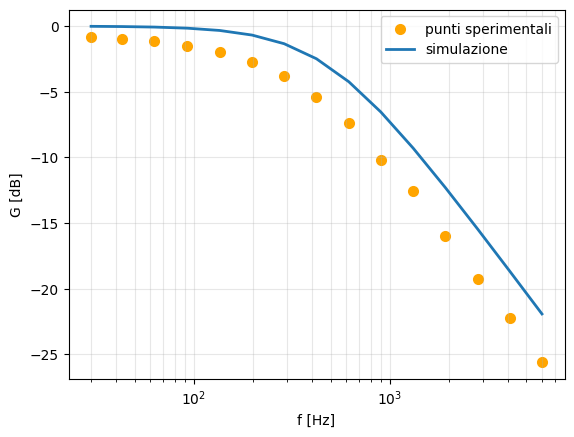

In [106]:
db_lab = 20 * np.log10(np.abs(G_lab))
db_sim = 20 * np.log10(np.abs(G_sim))
# if i put y_axis in log, there iss't the x20, is that  problem?  

plt.scatter(freqs, db_lab, linewidth=2, color='orange', label='punti sperimentali')
plt.plot(freqs, db_sim, linewidth=2, label='simulazione')


plt.xscale('log')
plt.ylabel('G [dB]')
plt.xlabel('f [Hz]')
plt.grid(True, which='both', alpha=0.3)
plt.legend()

plt.show()

## Part 6

### Part 2

here have no experimental data  

In [107]:
# bestfit_fourier_params(x,y)

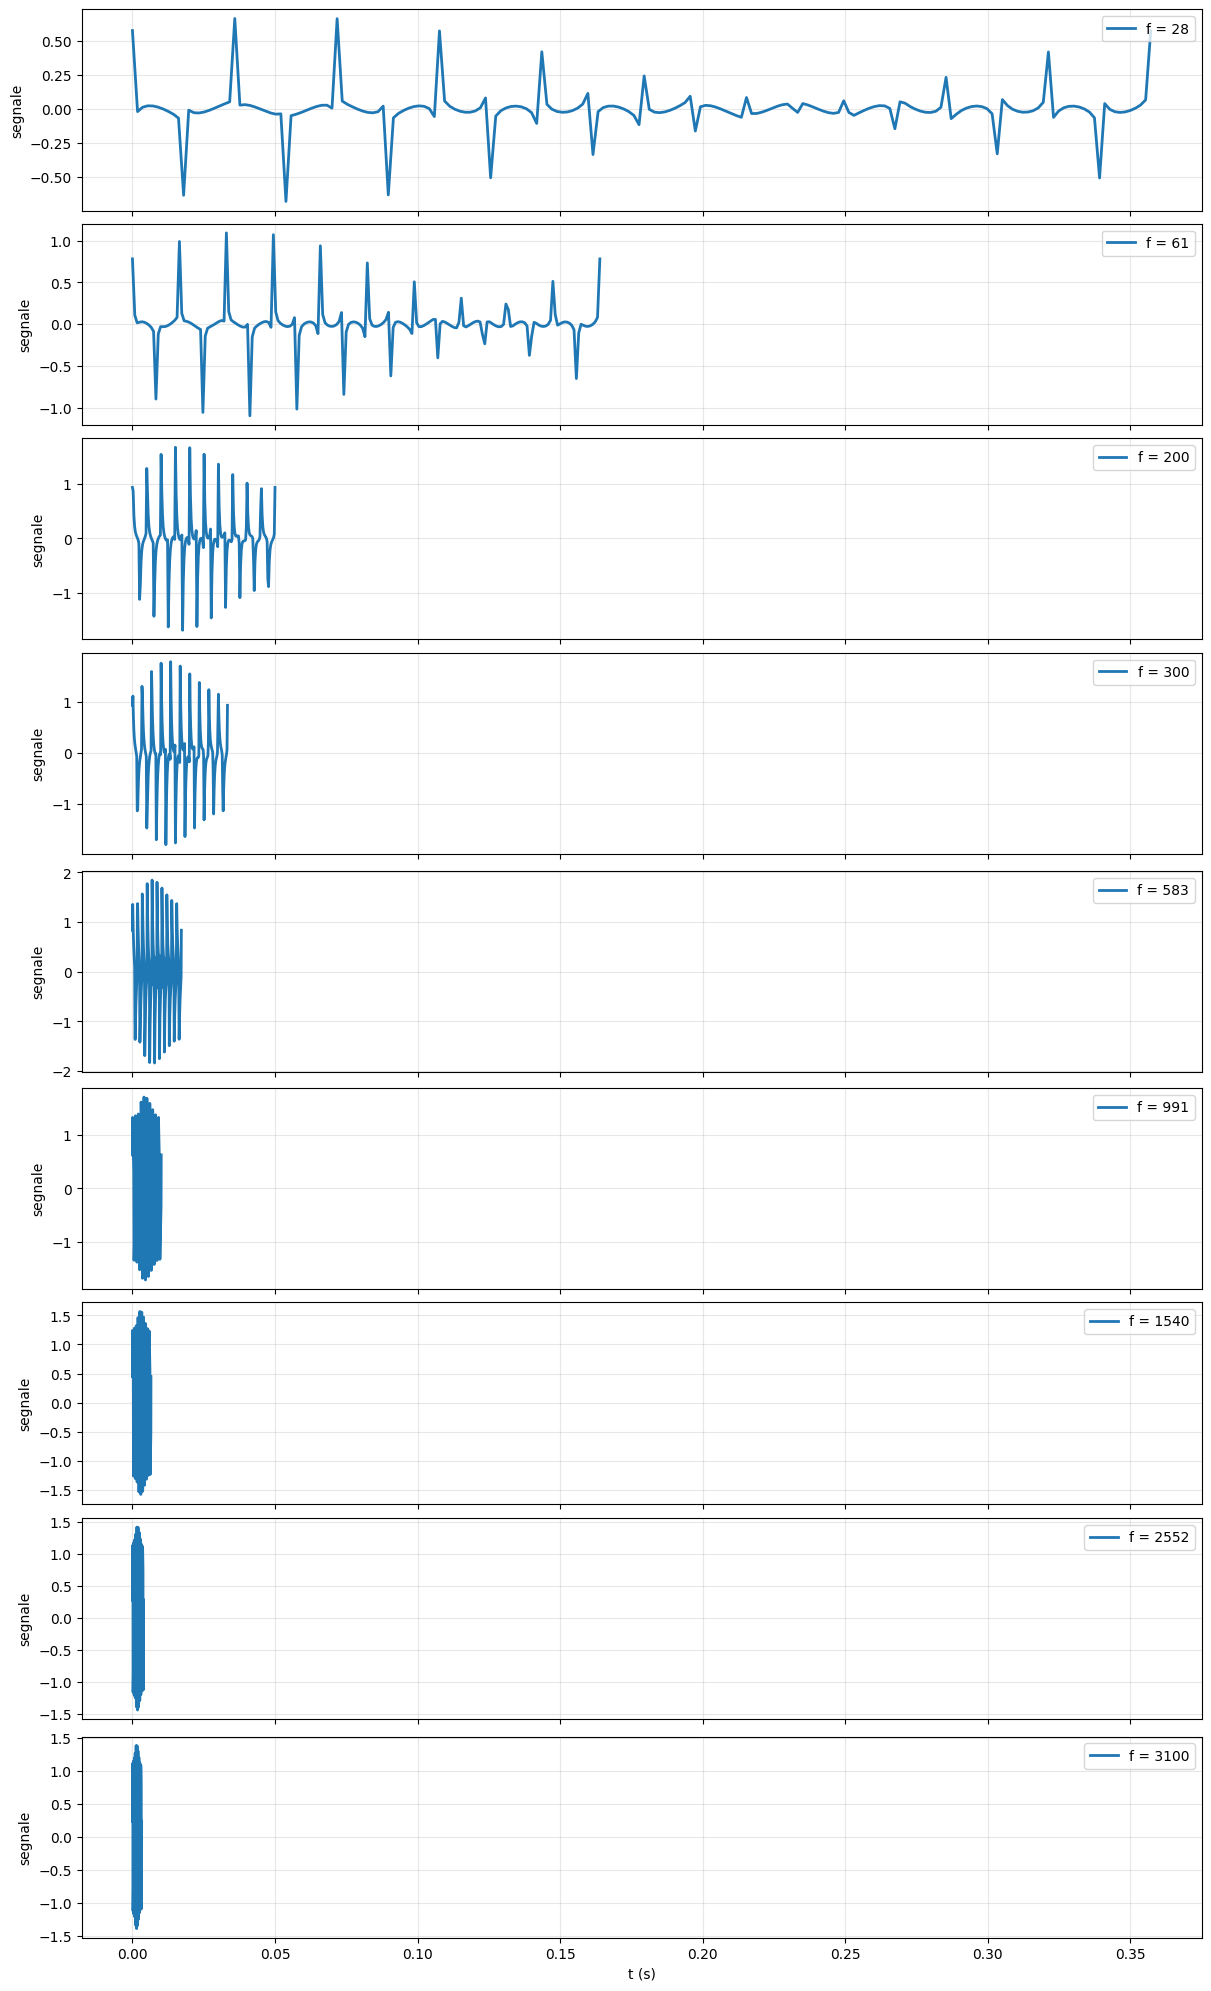

In [108]:
params1 = {
  'fc': 482,
  'A': 1,
  'offset': 10,
  't0': 0
}

freqs = [28, 61, 200, 300, 583, 991, 1540, 2552, 3100]
nums = [0,1,2,3,4,5,6,7,8]

N_harm = 21
rms_list = []
fig, axes = make_axes(freqs)


for ax, freq, i in zip(axes, freqs, nums):
    
    T = 1/freq
    t = np.linspace(0, 10*T, 200)    # diversi campionamenti

    y_hat = rc_derivator_output_from_square_fourier(
        t,                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=params1['t0'],
        fc=params1['fc'],
        N_harm=N_harm              # massima armonica (odd)
    )
    
    ax.plot(t, y_hat, linewidth=2.0, label=f"f = {freq}")
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")


axes[-1].set_xlabel("t (s)")
plt.show()

### Part 4

here have no experimental data  

In [109]:
# Simulate behaviour

G_sim = []
params1 = {
  'fc': 1000,
  'A': 2.9,
  'offset': 1,
  'phi0': 0,
  't0': 0,
}
N_harm = 25

freqs = [28, 61, 200, 300, 583, 991, 1540, 2552, 3100, 3500, 4000]
#fc è quella di prima??? non la sto passando???

for freq in freqs:  
    T = 1.0 / freq
    t = np.linspace(0, 10*T, 200)    # diversi campionamenti
    y_out, gains = rc_derivator_output_from_square_fourier(
        t,                         # x = array tempi (s)
        f0=freq,
        A=params1["A"],
        offset=params1["offset"],
        t0=params1["t0"],
        fc=params1['fc'],
        N_harm=N_harm,              # massima armonica (odd)
        want_gain=True
    )
    G_sim.append(gains)

In [110]:
G_sim

[np.float64(0.027989030449674355),
 np.float64(0.06088682524469269),
 np.float64(0.19611613513818404),
 np.float64(0.2873478855663454),
 np.float64(0.5036561529313862),
 np.float64(0.7039032254703337),
 np.float64(0.838692381993937),
 np.float64(0.9310704235687851),
 np.float64(0.9517086177605508),
 np.float64(0.9615239476408232),
 np.float64(0.9701425001453319)]

In [111]:
freqs

[28, 61, 200, 300, 583, 991, 1540, 2552, 3100, 3500, 4000]

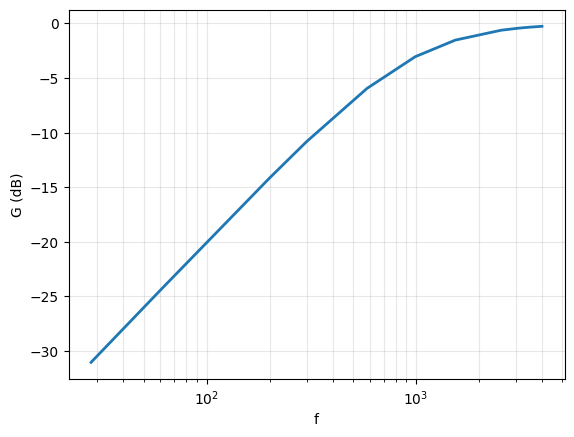

In [112]:
db_sim = 20 * np.log10(np.abs(G_sim))
# if i put y_axis in log, there iss't the x20, is that  problem?  

plt.plot(freqs, db_sim, linewidth=2)

plt.xscale('log')
plt.ylabel('G (dB)')
plt.xlabel('f')
plt.grid(True, which='both', alpha=0.3)

plt.show()

why can it go above the 0 line? isn't it impossible?   
maybe i caput put G/sim to 1 if they are bigger than 1?  
 
the version 2 is worse??? it doesn't have the straight part  

nota: Bode plots significa cosa succede se passo N_harm=1, quale è il gain della fondamentale di una certa frequenza?   
quindi nelle funzioni non devo ritornare gains[0], basta ritornare l'intero gains, ma devo mettere N_harm=1 così ho solo l'armonica principale  
perchè è quello che vuol dire fare un Bode plot    
part 2 and 4, can i put them together? do hey send same frequencies? or the second one sends a square, the fourth one sends pure harmonics of a specific freqency?  

## Part 7

forma quadra di bassa frequenza + high pass filter (accoppiamento AC)  

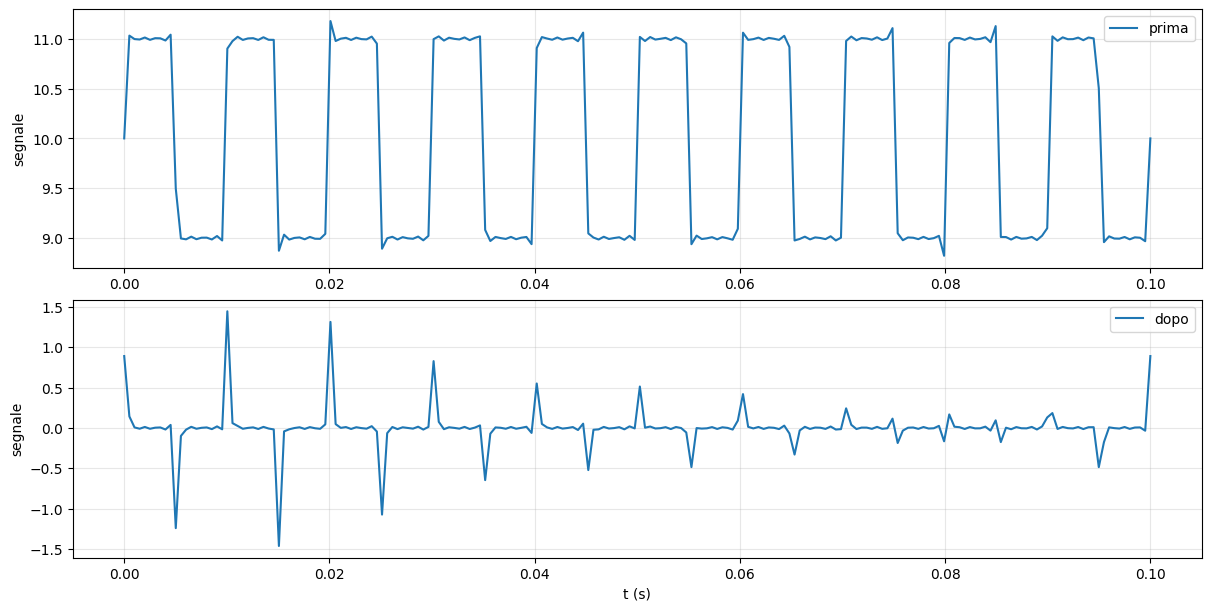

In [113]:
params1 = {'fc': 900,
  'A': 1,
  'offset': 10,
  'phi0': -0,
  't0': 0,
  'f0' : 100
}

N_harm = 51

T = 1/params1['f0']
t = np.linspace(0, 10*T, 200)    # diversi campionamenti

before, after = square_and_derivativeish(
        t,                         # x = array tempi (s)
        f0=params1['f0'],
        A=params1["A"],
        offset=params1["offset"],
        t0=params1['t0'],
        fc=params1['fc'],
        N_harm=N_harm              # massima armonica (odd)
    )


fig, ax = plt.subplots(
    nrows=2,
    ncols=1,
    sharex=False,
    figsize=(12, 3 * 2),
    constrained_layout=True
)

ax[0].plot(t, before, label='prima')
ax[1].plot(t, after, label='dopo')

ax[0].set_ylabel("segnale")
ax[1].set_ylabel("segnale")
ax[0].grid(True, alpha=0.3)
ax[1].grid(True, alpha=0.3)
ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

ax[-1].set_xlabel("t (s)")

plt.show()

## Part 8

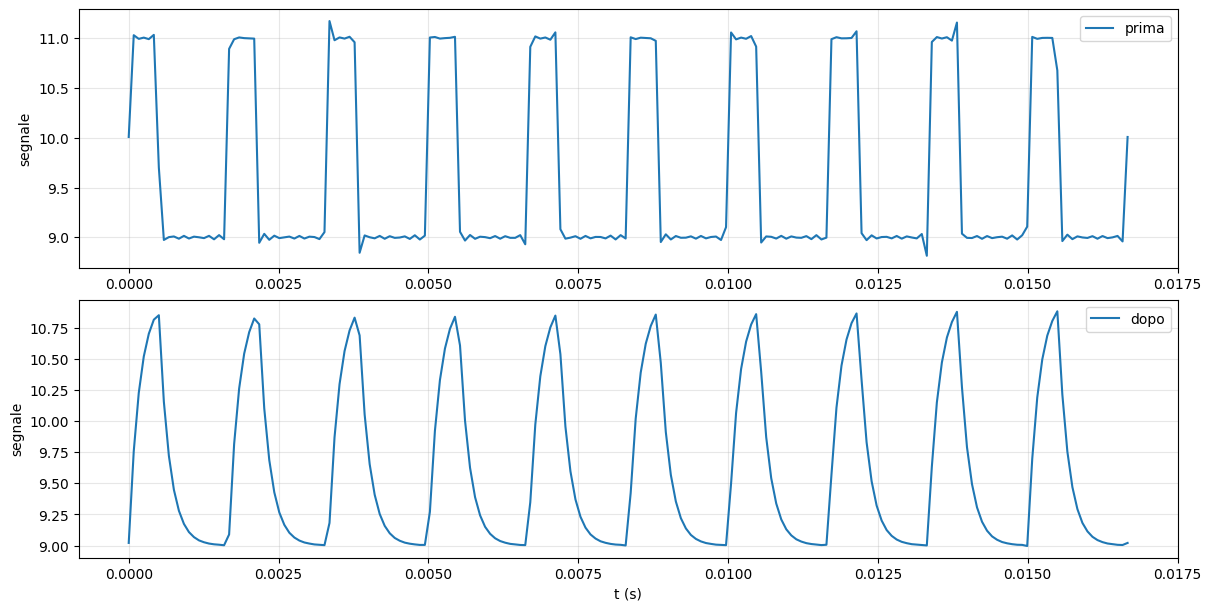

In [114]:
params1 = {'fc': 900,
  'A': 1,
  'offset': 10,
  'phi0': -0,
  't0': 0,
  'f0' : 600
}

N_harm = 51

T = 1/params1['f0']
t = np.linspace(0, 10*T, 200)    # diversi campionamenti

before, after = pulse_and_lowpass(
        t,                         # x = array tempi (s)
        f0=params1['f0'],
        A=params1["A"],
        offset=params1["offset"],
        t0=params1['t0'],
        fc=params1['fc'],
        N_harm=N_harm,              # massima armonica (odd)
        duty = 0.3
    )


fig, ax = plt.subplots(
    nrows=2,
    ncols=1,
    sharex=False,
    figsize=(12, 3 * 2),
    constrained_layout=True
)


ax[0].plot(t, before, label='prima')
ax[1].plot(t, after, label='dopo')

ax[0].set_ylabel("segnale")
ax[1].set_ylabel("segnale")
ax[0].grid(True, alpha=0.3)
ax[1].grid(True, alpha=0.3)
ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

ax[-1].set_xlabel("t (s)")

plt.show()